# 學生學習與作業版｜任務 8：分析報告與可重現性

**姓名：**何韋仁　**學號／組別：**C114118243　**完成日期：**2026/11/26

**學習目標：** 整理資料分析證據、記錄環境，建立可重跑的第一階段報告。

本單元與教師版「任務 8」相同標題、資料、教學順序與範例；除了明確標示的作業與填空，其餘教師版教材內容保留。對照重點：程式填空對應教師版「延伸：主張如何連結證據」。

### 如何完成
1. 先閱讀觀念與執行資料準備；各單元可以獨立啟動，不需要依賴上一單元的變數。
2. **💻 P 作業**：在指定程式 cell 補上 `____`，可先用提供的 Vibe Coding 提示詞詢問 AI。補完再執行，並執行後面的驗證 cell。未填時出現 `NameError` 是預期現象，先完成填空再繼續。
3. **📝 Q 作業**：查詢 AI、比較教材內容，填寫緊接的文字作答區；請記錄實際提示詞、自己的解釋與查證方式。
4. **🎯 M 小任務**：在任務 4、8、12、16 將前面幾單元整合成可執行的成果。不要只交 AI 回覆，要交實際程式、輸出與自己的解釋。
5. 把 Notebook 存到自己的 Google 雲端硬碟，完成後下載／依教師指示繳交 `.ipynb`；小任務保留輸出、文字與 AI 使用紀錄。

**案例限制：**本資料是公式生成的 60 筆模擬紀錄，不能推論真實學生或因果。缺失與 15 小時值在計分後加入。預測時欄位可得性是假設；全部資料已在前半段探索，後續切出的測試集僅示範流程，不能視為完全獨立的新資料。

**完成檢核：**本單元有 1 項程式填空、2 項 AI 查詢作答；若是任務 4、8、12、16，另外有 1 項整合小任務。請保留自己的輸出、回答和驗證紀錄。


## 共用資料準備
以下在記憶體重建與既有教材相同的資料。執行後可以直接開始本單元；不會覆寫 CSV。


In [ ]:
# 匯入套件：numpy 建立隨機資料，pandas 管理表格，pyplot 繪圖
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 固定種子，並維持呼叫順序，以重現原教材的 60 筆模擬資料
rng = np.random.default_rng(42)
n = 60
departments = ["資訊管理", "企業管理", "金融管理"]
# 每個字典鍵是一個欄位；對應的值是 60 名學生的資料
data = {
    "student_id": range(1, n + 1),
    "department": rng.choice(departments, n),
    "sleep_hours": rng.normal(6.7, 1.1, n).round(1),
    "screen_time_hours": rng.normal(5.0, 1.5, n).clip(1, 10).round(1),
    "study_hours": rng.normal(2.5, 1.0, n).clip(0.5, 6).round(1),
    "attendance_rate": rng.normal(88, 8, n).clip(60, 100).round(0),
}
df = pd.DataFrame(data)
# 成績依設定公式與隨機誤差建立；關係來自模擬規則，不能視為因果發現
noise = rng.normal(0, 5, n)
score = (50 + 3 * df["study_hours"] + 2 * df["sleep_hours"]
         - 1.2 * df["screen_time_hours"] + 0.15 * df["attendance_rate"] + noise)
df["quiz_score"] = score.clip(0, 100).round(0)
# 故意在計分後加入資料品質問題；無法從表格還原計分時原始值
df.loc[[5, 17], "sleep_hours"] = np.nan
df.loc[8, "screen_time_hours"] = 15.0
print("模擬資料形狀（列, 欄）：", df.shape)


模擬資料形狀（列, 欄）： (60, 7)


## 8.1 問題、證據、限制
報告必須對應資料與圖表，而非只有結論。對每個發現寫明使用欄位、有效筆數、處理方式及限制。


In [ ]:
# 重現兩項可核對的證據：品質與平均成績
print("形狀：", df.shape)
print("欄位缺失：\n", df.isna().sum())
print("平均成績：", df["quiz_score"].mean())
print("睡眠與成績有效配對：", len(df.dropna(subset=["sleep_hours", "quiz_score"])))


形狀： (60, 7)
欄位缺失：
 student_id           0
department           0
sleep_hours          2
screen_time_hours    0
study_hours          0
attendance_rate      0
quiz_score           0
dtype: int64
平均成績： 78.8
睡眠與成績有效配對： 58


## 📝 學生作業 08-Q1｜AI 查詢與作答：可重現性
**任務：**固定亂數種子是否足夠讓任何人在任何環境都得到完全相同結果？

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請說明種子、資料版本、套件版本、路徑與執行順序對 Notebook 重現性的影響。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 08-Q1 專用作答區：請雙擊此文字儲存格填寫
- **AI 工具及實際提示詞：** 使用 Claude，採用教材提供的提示詞。
- **AI 回答重點（請自行整理）：**
  1. 固定種子可以讓亂數一樣。
  2. 但套件版本或電腦不同，結果還是可能不同。
- **我的理解與具體例子：** 固定種子 42 不夠，還要記錄 Python 和套件版本。
- **查證來源／方式及日期（無法查證請註明）：** 2026/11/06 執行 8.2：Python 3.13.5、pandas 2.2.3、numpy 2.1.3、scikit-learn 1.6.1。
- **我檢查或修正 AI 回答的地方：** AI 沒提到要用相對路徑，教材有提醒不能用自己電腦的路徑。

## 8.2 紀錄套件與環境
固定種子有助重現，但不同套件版本或計算環境仍可能有差異。記錄資料檔與取得方式，使用相對路徑，不暴露個人電腦路徑。


In [ ]:
# 顯示環境資訊，不自動安裝或修改任何套件
import sys
import sklearn
import matplotlib
print("Python：", sys.version.split()[0])
print("numpy：", np.__version__, "pandas：", pd.__version__)
print("matplotlib：", matplotlib.__version__, "scikit-learn：", sklearn.__version__)


Python： 3.13.5
numpy： 2.1.3 pandas： 2.2.3
matplotlib： 3.10.0 scikit-learn： 1.6.1


## 📝 學生作業 08-Q2｜AI 查詢與作答：證據與主張
**任務：**一段分析報告如何讓讀者找到支持結論的數字及限制？

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請提供資料分析主張、對應表圖、有效筆數、限制的寫作架構，不要虛構我的結果。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 08-Q2 專用作答區：請雙擊此文字儲存格填寫
- **AI 工具及實際提示詞：** 使用 Claude，採用教材提供的提示詞。
- **AI 回答重點（請自行整理）：**
  1. 每個結論都要寫數字、筆數和怎麼處理資料。
  2. 限制也要寫出來。
- **我的理解與具體例子：** 例如寫「睡眠和成績相關 -0.015（58 筆）」，比只寫「睡眠沒影響」清楚。
- **查證來源／方式及日期（無法查證請註明）：** 2026/11/06 執行 8.1：平均成績 78.8，睡眠配對 58 筆。
- **我檢查或修正 AI 回答的地方：** 我把例子換成實際跑出來的數字。

## 8.3 第一階段報告框架
1. 問題、模擬資料來源與欄位。
2. 缺失、異常、重複的實際結果與處理理由。
3. 至少兩張圖、分組與變數關係。
4. 處理方案比較及限制。
5. AI 提示詞、人工修改、錯誤及驗證。
6. 重啟環境由上到下執行，檢查數字與報告一致。

**注意：**本階段已看過全體 60 筆，後續切出的測試資料不屬於完全未接觸過的新資料。


## 範例：主張如何連結證據
不要只寫「睡眠越多成績越高」。較好的描述是：先寫資料與有效樣本數，再呈現實際相關係數與圖表，最後揭露生成公式與因果限制。

**請學生核對：**輸出中的數字是否與報告文字一致？如不同應以重跑結果為準，不能要求 AI 猜數字。


## 💻 學生作業 08-P1｜Vibe Coding 程式填空
**對應教師版：**任務 8「延伸：主張如何連結證據」的示範程式。

**任務：**建立 sleep_hours 與 quiz_score 都有效的 pairs，後續報告會計算筆數及相關。

**執行方式：**找到下一個程式儲存格中的 `____`，使用自己撰寫或 AI 建議的程式補齊，保留其他已提供的程式與註解。補完後先執行該 cell，再執行緊接的自動檢查；後續單元內容可能依賴此變數。

**可使用的 Vibe Coding 提示詞：**
```text
我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。
我的任務是：建立 sleep_hours 與 quiz_score 都有效的 pairs，後續報告會計算筆數及相關。
請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。
```
完成後記錄實際使用的提示詞與自己改動的地方。


In [ ]:
# 用同一批有效資料計算筆數與係數，供報告引用
pairs = df.dropna(subset=["sleep_hours", "quiz_score"]).copy()
report_evidence = {"有效配對": len(pairs),
                   "睡眠與分數相關": pairs["sleep_hours"].corr(pairs["quiz_score"]),
                   "限制": "模擬資料、成績由公式生成，不能推論因果"}
print(report_evidence)

{'有效配對': 58, '睡眠與分數相關': np.float64(-0.015255866695473633), '限制': '模擬資料、成績由公式生成，不能推論因果'}


### ✅ 作業 08-P1｜執行驗證
執行下方程式，並同時檢查上方實際輸出。自動檢查只涵蓋主要條件；如果圖表、說明或資料來源不符任務，仍需人工修正。


In [ ]:
assert pairs[["sleep_hours", "quiz_score"]].notna().all().all()
assert len(pairs) == len(df.dropna(subset=["sleep_hours", "quiz_score"]))
print("檢查通過：報告使用的有效配對正確。")


檢查通過：報告使用的有效配對正確。


### ✍️ 作業 08-P1｜我的完成紀錄
- **我實際使用的提示詞（若未使用 AI 請註明）：** 使用 Claude，採用教材提供的提示詞。
- **我補上的程式在做什麼：** `df.dropna(subset=["sleep_hours", "quiz_score"]).copy()`，留睡眠和成績都有值的列。
- **執行或驗證遇到的問題與修正：** 沒有遇到錯誤。
- **檢查結果及我如何確認：** 驗證通過，有效配對 58 筆，相關 -0.015。

## 本單元學習收束與 AI 使用紀錄

請學生先用自己的話解釋一個關鍵觀念，再指出一個執行結果及驗證方式。記錄：使用的提示詞、AI 回答中檢查或修改的地方、遇到的問題、修正後的證據與本資料限制。

**通用提示詞**：我是 Python 初學者，請逐步協助我完成上面的任務；每段程式加繁體中文註解，說明輸入、處理與輸出，提供兩項可實際執行的驗證，保留原始資料，不要虛構執行結果。


## 🎯 學生小任務 MB｜分析問題與證據報告
**涵蓋：**任務 5～8。這是需要獨立完成、可繳交的整合成果。

### 任務要求
以「學習行為與成績」為問題，至少完成一次科系的分組筆數與平均、一次含有效配對數的相關分析，以及一張圖；比較保留／排除螢幕時間大於 10 的結果。文字報告須引述實際數字、資料生成限制與可重跑資訊。

### 可使用的 AI 提示詞
```text
我是 Python 初學者，請協助我完成以下資料分析小任務：
請協助我規劃資料分析報告：包含分組人數和平均、有效配對、圖表與 15 小時紀錄的兩種處理比較。保留 df、不要憑空填寫結果，並指出因果推論限制。
請拆成小步驟，提供繁體中文教學註解、預期輸出應如何檢查，並提醒不能從這份模擬資料推論因果。
```

### 執行與交付
- 在下一個程式儲存格自行填入程式，先執行本 Notebook 上方的資料準備及必要 cell。若需要更多儲存格可以自行新增。
- 輸出應保留在 Notebook 中；在後面的文字區填寫實際數字與自己的解釋。
- **工具提示：**groupby、dropna、corr、plt.scatter；先重建本單元 df。
- 至少記錄一項實際檢查及一項資料限制。交付完成後的 `.ipynb`，含程式、輸出及 AI 使用紀錄。


科系分組：


,count,mean,median
department,,,
企業管理,21,80.67,81.0
資訊管理,15,79.73,80.0
金融管理,24,76.58,76.5


study_hours 有效配對： 60 相關係數： 0.471
sleep_hours 有效配對： 58 相關係數： -0.015
screen_time_hours 有效配對： 60 相關係數： -0.364


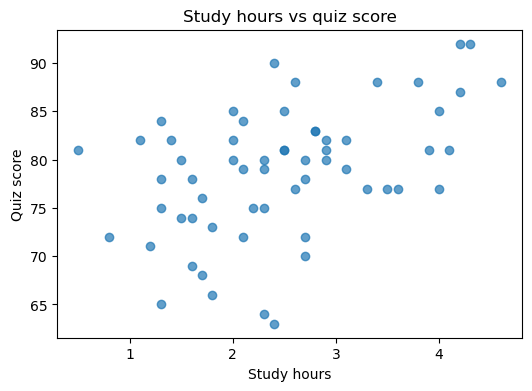

,方案,筆數,螢幕與成績相關
0,保留 15 小時,60,-0.364
1,排除 > 10 小時,59,-0.509


pandas 2.2.3 numpy 2.1.3 ；資料由種子 42 在記憶體產生
檢查通過：df 仍為 60 筆。


In [ ]:
# 學生小任務 MB：分析問題與證據報告（不修改 df）
# 1. 科系分組：人數與平均
group_table = df.groupby("department")["quiz_score"].agg(["count", "mean", "median"]).round(2)
print("科系分組：")
display(group_table)

# 2. 相關分析（附有效配對數）
for col in ["study_hours", "sleep_hours", "screen_time_hours"]:
    valid = df.dropna(subset=[col, "quiz_score"])
    print(col, "有效配對：", len(valid), "相關係數：", round(valid[col].corr(valid["quiz_score"]), 3))

# 3. 圖：讀書時數 vs 成績
plt.figure(figsize=(6, 4))
plt.scatter(df["study_hours"], df["quiz_score"], alpha=0.7)
plt.xlabel("Study hours"); plt.ylabel("Quiz score")
plt.title("Study hours vs quiz score")
plt.show()

# 4. 螢幕時間 > 10 保留／排除比較
keep = df.dropna(subset=["screen_time_hours", "quiz_score"])
drop = keep[keep["screen_time_hours"] <= 10]
compare = pd.DataFrame({
    "方案": ["保留 15 小時", "排除 > 10 小時"],
    "筆數": [len(keep), len(drop)],
    "螢幕與成績相關": [round(keep["screen_time_hours"].corr(keep["quiz_score"]), 3),
                    round(drop["screen_time_hours"].corr(drop["quiz_score"]), 3)]})
display(compare)

# 5. 可重跑資訊
print("pandas", pd.__version__, "numpy", np.__version__, "；資料由種子 42 在記憶體產生")
assert len(df) == 60
print("檢查通過：df 仍為 60 筆。")

### ✍️ 小任務 MB｜結果與檢核（請雙擊填寫）
- **問題及使用的資料／欄位：** 學習行為和成績有什麼關係；用 department、study_hours、sleep_hours、screen_time_hours、quiz_score。
- **實際輸出與至少一項依據數字的觀察：** 科系平均：企管 80.67（21 人）、資管 79.73（15 人）、金管 76.58（24 人）。讀書相關 0.471（60 筆），睡眠 -0.015（58 筆），螢幕 -0.364（60 筆）。
- **圖表或模型結果的解讀（依任務要求）：** 散布圖看得出讀書越多分數大致越高。排除 15 小時那筆後，螢幕相關從 -0.364 變 -0.509，結果對這筆很敏感。
- **資料品質、模擬資料或評估限制：** 資料是公式模擬的 60 筆，不能推論因果；睡眠缺 2 筆；15 小時是計分後才加入的。
- **驗證方法與結果：** 用 assert 確認 df 還是 60 筆；相關的筆數和 06、07 的結果一樣。
- **AI 工具、實際提示詞、人工修改與遇到的問題：** 使用 Claude，採用教材提供的提示詞。我確認每個相關係數都有印出配對數。
- **重新執行是否成功及環境或檔案需求：** 重新啟動後由上到下執行成功；只需 numpy、pandas、matplotlib、scikit-learn，資料在程式中產生，不用上傳 CSV。